# Cross-Generator, Cross-Lingual & Cross-Modality LLM-Phishing Detection

Label-free domain adaptation (CORAL vs. self-training) for lightweight phishing detectors, across a 3-axis domain grid: **generator** (ChatGPT/Grok/Perplexity) x **language** (EN/FR/AR) x **modality** (email/SMS).

**Generation is MANUAL** (chat interface, no API): paste prompts into each chat model, save replies as text files, this notebook ingests them.

### Ethics
Synthetic phishing/smishing is generated only to build a labeled corpus for a **defensive detector**; logged, released, never sent. Prompts use placeholder links and no real personal data.

### Reproducibility (chat models)
Record each model's exact name + date in `MODEL_VERSIONS`, release the generated corpus. Use three genuinely different models (in Perplexity pick a backend distinct from GPT/Grok, search OFF).

### Run order
Part 1 config -> Part 2 library -> Part 2b embeddings -> **Part 3 smoke test (no data needed)** -> Part 4 prompts -> Part 5 manual -> Part 6 ingest -> Part 7 real corpora -> Part 8 domains -> Part 9 run -> Part 10 stats.

In [2]:
!pip install pandas scikit-learn scipy matplotlib
# optional, for Representation B (embeddings):
!pip install sentence-transformers


[notice] A new release of pip is available: 25.2 -> 26.1.2
[notice] To update, run: pip install --upgrade pip

[notice] A new release of pip is available: 25.2 -> 26.1.2
[notice] To update, run: pip install --upgrade pip


## Part 1 — Configuration

In [3]:
import re, json, hashlib, glob, warnings
from pathlib import Path
import numpy as np, pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import matthews_corrcoef, f1_score
from scipy.linalg import sqrtm
from scipy.stats import wilcoxon
warnings.filterwarnings("ignore")
np.random.seed(0)

ROOT     = Path(".")
GEN_DIR  = ROOT/"data"/"generated"; GEN_DIR.mkdir(parents=True, exist_ok=True)
REAL_DIR = ROOT/"data"/"real";      REAL_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR  = ROOT/"results";          OUT_DIR.mkdir(parents=True, exist_ok=True)

LANGS      = {"en": "English", "fr": "French", "ar": "Modern Standard Arabic"}
MODALITIES = ["email", "sms"]                       # the 3rd controlled axis
GENERATORS = ["chatgpt", "grok", "perplexity"]      # chat-interface, NO API
MODEL_VERSIONS = {
    "chatgpt":    "FILL: e.g. GPT-4o (2026-06)",
    "grok":       "FILL: e.g. Grok-3 (2026-06)",
    "perplexity": "FILL: underlying model, search OFF (2026-06)",
}
SEP = "#####"   # separator the models place between messages

SCENARIOS = [
    {"id": "s01", "pretext": "bank account suspended, verify identity"},
    {"id": "s02", "pretext": "package held by customs, pay a small fee"},
    {"id": "s03", "pretext": "tax authority refund, confirm bank details"},
    {"id": "s04", "pretext": "email/account storage full, re-login to keep account"},
    {"id": "s05", "pretext": "prize/lottery win, claim within 24h"},
    {"id": "s06", "pretext": "IT department password expiry, reset now"},
    {"id": "s07", "pretext": "unpaid invoice from a supplier"},
    {"id": "s08", "pretext": "HR document requires re-authentication"},
    {"id": "s09", "pretext": "streaming subscription payment failed"},
    {"id": "s10", "pretext": "shipping company delivery reschedule link"},
    {"id": "s11", "pretext": "government benefit / social security update"},
    {"id": "s12", "pretext": "bank card blocked for suspicious activity"},
    {"id": "s13", "pretext": "shared cloud document needs sign-in"},
    {"id": "s14", "pretext": "utility bill overdue, disconnection warning"},
    {"id": "s15", "pretext": "charity donation urgent appeal"},
    {"id": "s16", "pretext": "job offer requiring an upfront processing fee"},
    {"id": "s17", "pretext": "two-factor code confirmation request"},
    {"id": "s18", "pretext": "login from a new device, confirm it was you"},
]
print("config:", len(SCENARIOS), "scenarios x", len(GENERATORS), "generators x",
      len(LANGS), "languages x", len(MODALITIES), "modalities")

config: 18 scenarios x 3 generators x 3 languages x 2 modalities


## Part 1b — Data prep: convert your downloaded raw files -> `data/real/{lang}_{modality}.csv`

Reads the exact files you placed under `data/real/{french,arabic}/...` and writes normalized CSVs (`text,label,lang,modality`) that Part 7 loads. English (MeAJOR + UCI) is the only cell you still fetch.

In [4]:
import json as _json, glob as _glob
def _write_norm(df, lang, mod):
    df = df[["text", "label"]].dropna(); df = df[df.text.astype(str).str.len() > 3]
    df = df.assign(lang=lang, modality=mod)
    out = REAL_DIR / f"{lang}_{mod}.csv"; df.to_csv(out, index=False, encoding="utf-8")
    print(f"  {out.name}: {len(df)} (phish={int((df.label==1).sum())}, legit={int((df.label==0).sum())})")

# FR email  <- french/email/data.jsonl (text, label ham/spam)  [native]
p = REAL_DIR / "french" / "email" / "data.jsonl"
if p.exists():
    df = pd.DataFrame([_json.loads(l) for l in open(p, encoding="utf-8")])
    df["label"] = (df["label"].astype(str).str.lower() != "ham").astype(int)
    _write_norm(df, "fr", "email")

# AR email  <- arabic/email/arabic_phishing_dataset_10k.csv (id,text,label 0/1)  [native 10k]
p = REAL_DIR / "arabic" / "email" / "arabic_phishing_dataset_10k.csv"
if p.exists():
    df = pd.read_csv(p); df.columns = [c.strip().lstrip("﻿") for c in df.columns]
    df["label"] = pd.to_numeric(df["label"], errors="coerce").fillna(0).astype(int)
    _write_norm(df, "ar", "email")

# AR sms  <- dialectal phishing csv + legit/*.txt  [native]
frames = []
p = REAL_DIR / "arabic" / "sms" / "dialectal_arabic_phishing_dataset.csv"
if p.exists():
    df = pd.read_csv(p, engine="python", on_bad_lines="skip"); df.columns = [c.strip().lstrip("﻿") for c in df.columns]
    lab = df.columns[-1]
    df["label"] = df[lab].astype(str).str.lower().str.contains("phish|spam|fraud|scam").astype(int)
    frames.append(df[["text", "label"]])
legit = _glob.glob(str(REAL_DIR / "arabic" / "sms" / "legit" / "*.txt"))
if legit:
    frames.append(pd.DataFrame({"text": [open(f, encoding="utf-8", errors="replace").read().strip() for f in legit], "label": 0}))
if frames:
    _write_norm(pd.concat(frames, ignore_index=True), "ar", "sms")

# EN email  <- english/en_email.csv (rich CSV: subject/body/... + label 0/1)
p = REAL_DIR / "english" / "en_email.csv"
if p.exists():
    df = pd.read_csv(p, on_bad_lines="skip", engine="python")
    df["text"] = df.get("subject", "").fillna("").astype(str) + "  " + df["body"].fillna("").astype(str)
    df["label"] = pd.to_numeric(df["label"], errors="coerce")
    df = df.dropna(subset=["label"]); df["label"] = df["label"].astype(int)
    _write_norm(df, "en", "email")

# EN sms  <- english/en_sms.csv (raw UCI: TAB-separated, NO header, col0=ham/spam col1=text)
p = REAL_DIR / "english" / "en_sms.csv"
if p.exists():
    df = pd.read_csv(p, sep="\t", header=None, names=["label", "text"],
                     quoting=3, on_bad_lines="skip", engine="python")
    df["label"] = (df["label"].astype(str).str.lower().str.strip() == "spam").astype(int)
    _write_norm(df, "en", "sms")

# still-missing cells
for lang, mod, hint in [("en", "email", "MeAJOR: zenodo.org/records/18471483"),
                        ("en", "sms",   "UCI SMS Spam: archive.ics.uci.edu/dataset/228")]:
    if not (REAL_DIR / f"{lang}_{mod}.csv").exists():
        print(f"  TODO download {lang}_{mod}: {hint}")
print("data prep done. FR sms = generation-only (no native corpus; both classes generated).")

  fr_email.csv: 2000 (phish=1000, legit=1000)
  ar_email.csv: 10000 (phish=4978, legit=5022)
  ar_sms.csv: 572 (phish=270, legit=302)
  en_email.csv: 108684 (phish=48034, legit=60650)
  en_sms.csv: 5562 (phish=747, legit=4815)
data prep done. FR sms = generation-only (no native corpus; both classes generated).


## Part 2 — Core library (features, detectors, adaptation, evaluation)

Two feature **representations** share the same detectors and adaptation: (A) hand-crafted stylometric + char-n-grams (here) and (B) frozen multilingual embeddings (Part 2b). Comparing A vs B is RQ3. Extractors are **fit on the source domain only** — that keeps the label-free guarantee honest. Detector training is CPU-only.

In [5]:
# ---- features (Representation A) ----
def numeric_features(text):
    t = text; n = max(len(t), 1); words = t.split(); low = t.lower()
    return np.array([
        len(t),
        len(words),
        low.count("http") + low.count("hxxp") + low.count("www"),
        sum(c.isdigit() for c in t) / n,
        sum(c.isupper() for c in t) / n,
        t.count("!") / n,
        t.count("?") / n,
        low.count("verify")+low.count("account")+low.count("urgent")+low.count("password"),  # EN cues (weak cross-lingual on purpose - RQ3)
        low.count("click")+low.count("login")+low.count("confirm"),
        len(set(words)) / max(len(words), 1),
    ], dtype=float)
# TODO(paper): add the 17 stylometric features from ref [2] per their definitions.

def make_transform(source_texts):
    Xn = np.vstack([numeric_features(t) for t in source_texts])
    scaler = StandardScaler().fit(Xn)
    vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5),
                          min_df=2, max_features=1500).fit(source_texts)
    def transform(texts):
        Xn = scaler.transform(np.vstack([numeric_features(t) for t in texts]))
        Xc = vec.transform(texts).toarray()
        return np.hstack([Xn, Xc])
    return transform

# ---- detectors ----
def make_model(name):
    if name == "logreg": return LogisticRegression(max_iter=1000, C=1.0)
    if name == "rf":     return RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=0)
    if name == "svm":    return SVC(kernel="linear", probability=True, C=1.0)
    raise ValueError(name)

# ---- adaptation ----
def coral(Xs, Xt, eps=1e-5):
    Cs = np.cov(Xs, rowvar=False) + eps*np.eye(Xs.shape[1])
    Ct = np.cov(Xt, rowvar=False) + eps*np.eye(Xt.shape[1])
    A = np.real(sqrtm(np.linalg.inv(sqrtm(Cs))) @ sqrtm(Ct))
    return Xs @ A

def recalibrate_threshold(scores, prior=0.5):
    return np.quantile(scores, 1 - prior)   # no labels used

def self_train(name, Xs, ys, Xt, rounds=5, margin=0.9):
    X, y = Xs.copy(), ys.copy(); used = np.zeros(len(Xt), bool)
    m = make_model(name); m.fit(X, y)
    for _ in range(rounds):
        p = m.predict_proba(Xt)[:, 1]
        conf = (p > margin) | (p < 1 - margin); new = conf & ~used
        if not new.any(): break
        X = np.vstack([X, Xt[new]]); y = np.concatenate([y, (p[new] > 0.5).astype(int)]); used |= new
        m = make_model(name); m.fit(X, y)
    return m

# ---- evaluation of one source->target pair ----
def evaluate_pair(src, tgt_pool, method, model_name, seed=0, frozen_test=None, transform_factory=None):
    rng = np.random.RandomState(seed)
    if frozen_test is not None:
        test = frozen_test; pool = tgt_pool
    else:
        idx = rng.permutation(len(tgt_pool)); cut = max(len(tgt_pool)//2, 1)
        test = tgt_pool.iloc[idx[:cut]]; pool = tgt_pool.iloc[idx[cut:]]
    if len(test) < 4 or len(pool) < 4: return np.nan, np.nan
    transform = (transform_factory or make_transform)(list(src.text))
    Xs = transform(list(src.text)); ys = src.label.values
    Xpool = transform(list(pool.text)); Xtest = transform(list(test.text)); ytest = test.label.values
    if method == "naive":
        m = make_model(model_name); m.fit(Xs, ys); yp = m.predict(Xtest)
    elif method == "coral":
        Xa = coral(Xs, Xpool); m = make_model(model_name); m.fit(Xa, ys)
        sc = m.predict_proba(Xtest)[:, 1]
        tau = recalibrate_threshold(m.predict_proba(Xpool)[:, 1]); yp = (sc >= tau).astype(int)
    elif method == "selftrain":
        m = self_train(model_name, Xs, ys, Xpool); yp = m.predict(Xtest)
    elif method == "upper":   # ceiling: uses TARGET labels (unavailable in deployment)
        m = make_model(model_name); m.fit(Xpool, pool.label.values); yp = m.predict(Xtest)
    else:
        raise ValueError(method)
    return matthews_corrcoef(ytest, yp), f1_score(ytest, yp, zero_division=0)

# ---- 3-axis regime: domain name = "generator|language|modality" ----
def regime(a, b):
    ga, la, ma = a.split("|"); gb, lb, mb = b.split("|")
    diffs = []
    if ga != gb: diffs.append("generator")
    if la != lb: diffs.append("language")
    if ma != mb: diffs.append("modality")
    if not diffs: return "intra"
    return diffs[0] if len(diffs) == 1 else "+".join(diffs)

def run_matrix(domains, frozen_tests=None, model_name="logreg",
               methods=("naive", "coral", "selftrain", "upper"), seeds=range(3),
               transform_factory=None):
    frozen_tests = frozen_tests or {}
    rows = []; names = list(domains)
    for a in names:
        for b in names:
            if a == b: continue
            ft = frozen_tests.get(b)
            for meth in methods:
                vals = [evaluate_pair(domains[a], domains[b], meth, model_name, s, ft, transform_factory) for s in seeds]
                mcc = np.nanmean([v[0] for v in vals]); f1 = np.nanmean([v[1] for v in vals])
                rows.append(dict(src=a, tgt=b, regime=regime(a, b), method=meth,
                                 mcc=round(mcc, 4), f1=round(f1, 4)))
    return pd.DataFrame(rows)

print("library ready")

library ready


### Part 2b — Representation B: frozen multilingual embeddings (optional)

Small multilingual encoder as a FROZEN feature extractor (no fine-tuning) -> stays lightweight, maps EN/FR/AR into a shared space. Needs `pip install sentence-transformers`; skips gracefully if absent. Default `paraphrase-multilingual-MiniLM-L12-v2` (~118M); swap to `sentence-transformers/LaBSE` for stronger alignment.

In [6]:
EMB_MODEL_NAME = "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
_emb_model = None
def _get_emb_model():
    global _emb_model
    if _emb_model is None:
        from sentence_transformers import SentenceTransformer   # pip install sentence-transformers
        _emb_model = SentenceTransformer(EMB_MODEL_NAME)         # uses GPU automatically if present
    return _emb_model

_emb_cache = {}
def _embed(texts):
    todo = [t for t in texts if t not in _emb_cache]
    if todo:
        vecs = _get_emb_model().encode(todo, batch_size=64, normalize_embeddings=True, show_progress_bar=False)
        for t, v in zip(todo, vecs): _emb_cache[t] = np.asarray(v, dtype=float)
    return np.vstack([_emb_cache[t] for t in texts])

def make_embedding_transform(source_texts):
    scaler = StandardScaler().fit(_embed(list(source_texts)))   # only a scaler is fit, on SOURCE
    def transform(texts):
        return scaler.transform(_embed(list(texts)))
    return transform

def embeddings_available():
    try:
        import sentence_transformers  # noqa
        return True
    except Exception:
        return False

print("Representation B (frozen embeddings) available:", embeddings_available())

Skipping import of cpp extensions due to incompatible torch version. Please upgrade to torch >= 2.11.0 (found 2.9.0).
W0719 20:42:15.261000 9507 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


Representation B (frozen embeddings) available: True


## Part 3 — Smoke test (no real data needed)

Runs the whole 3-axis pipeline on synthetic data to prove it executes and metrics compute. NOT a result — only checks the plumbing.

In [7]:
def synth_domain(gen, lang, mod, n=140, seed=0):
    rng = np.random.RandomState(seed)
    fillers = {"en": ["meeting","report","team","today","project","schedule"],
               "fr": ["reunion","rapport","equipe","aujourdhui","projet","agenda"],
               "ar": ["ijtimaa","taqrir","fariq","alyawm","mashru","jadwal"]}
    phish = ["verify account urgent", "click login confirm password", "account suspended verify now"]
    rows = []
    for i in range(n):
        lab = int(i % 2 == 0)
        base = " ".join(rng.choice(fillers[lang], 4 if mod == "email" else 2))  # sms shorter
        txt = (rng.choice(phish) + " " + base + f" {gen} {mod}") if lab else (base + f" regards {gen} {mod}")
        rows.append(dict(text=txt, label=lab, generator=gen, lang=lang, modality=mod))
    return pd.DataFrame(rows)

_dom = {f"{g}|{l}|{m}": synth_domain(g, l, m, seed=(hash((g, l, m)) % 1000))
        for g in ["human", "chatgpt"] for l in ["en", "fr"] for m in ["email", "sms"]}
_res = run_matrix(_dom, seeds=range(2))
print(_res.groupby(["regime", "method"]).mcc.mean().round(2))
assert not _res.empty and "modality" in set(_res.regime)
print("\nSMOKE TEST OK - 3-axis pipeline runs (generator/language/modality regimes present)")

regime                       method   
generator                    coral        0.92
                             naive        1.00
                             selftrain    1.00
                             upper        1.00
generator+language           coral        0.92
                             naive        1.00
                             selftrain    1.00
                             upper        1.00
generator+language+modality  coral        0.93
                             naive        0.70
                             selftrain    0.69
                             upper        1.00
generator+modality           coral        0.91
                             naive        0.62
                             selftrain    0.61
                             upper        1.00
language                     coral        0.91
                             naive        1.00
                             selftrain    1.00
                             upper        1.00
language+modality    

## Part 4 — Print the generation prompts to paste

Run this, then paste each block into **ChatGPT**, **Grok**, **Perplexity** (one language x modality at a time). Ask each to continue a few times to reach ~500+ per cell. `per_scenario` trades round-trips for volume.

In [8]:
def build_paste_prompt(lang_key, modality, per_scenario=3):
    lname = LANGS[lang_key]
    if modality == "email":
        kind = "phishing EMAILS"
        fmt  = "Begin each with 'SCENARIO: <id>', then a Subject line, then the body."
    else:
        kind = "smishing SMS TEXT MESSAGES (short, max ~2 sentences, no subject line)"
        fmt  = "Begin each with 'SCENARIO: <id>', then the single short message."
    header = (
        f"You are helping build a labeled dataset to TRAIN a phishing DETECTOR. "
        f"Generate realistic SYNTHETIC {kind} for defensive research only; they will never be sent. "
        f"Write natural, native {lname}. Use placeholder links like hxxp://verify-example[.]tld and NO real "
        f"personal data or real URLs. Produce {per_scenario} DISTINCT items for EACH scenario below. "
        f"Separate EVERY item with a line containing only {SEP}. {fmt}\n\nScenarios:")
    body = "\n".join(f"- {s['id']}: {s['pretext']}" for s in SCENARIOS)
    return header + "\n" + body

def build_benign_prompt(lang_key, modality, per=40):
    lname = LANGS[lang_key]
    kind = "SMS text messages" if modality == "sms" else "emails"
    return (f"Generate {per} ordinary, HARMLESS everyday {kind} in native {lname} "
            f"(chit-chat, reminders, appointments, opted-in business notices) for the LEGITIMATE class of a "
            f"phishing-detection dataset. No links, no requests for credentials. Separate each with a line {SEP}.")

for lk in LANGS:
    for mod in MODALITIES:
        print("=" * 80)
        print(f"LANGUAGE={lk}  MODALITY={mod}   -> paste into ChatGPT, then Grok, then Perplexity")
        print("=" * 80)
        print(build_paste_prompt(lk, mod))
        print()

# BENIGN (legit) generation - only needed where no human legit exists (French SMS).
print("#" * 80)
print("BENIGN/LEGIT prompt for FRENCH SMS (no native corpus) -> save as legit_{generator}_fr_sms.txt")
print("#" * 80)
print(build_benign_prompt("fr", "sms"))

LANGUAGE=en  MODALITY=email   -> paste into ChatGPT, then Grok, then Perplexity
You are helping build a labeled dataset to TRAIN a phishing DETECTOR. Generate realistic SYNTHETIC phishing EMAILS for defensive research only; they will never be sent. Write natural, native English. Use placeholder links like hxxp://verify-example[.]tld and NO real personal data or real URLs. Produce 3 DISTINCT items for EACH scenario below. Separate EVERY item with a line containing only #####. Begin each with 'SCENARIO: <id>', then a Subject line, then the body.

Scenarios:
- s01: bank account suspended, verify identity
- s02: package held by customs, pay a small fee
- s03: tax authority refund, confirm bank details
- s04: email/account storage full, re-login to keep account
- s05: prize/lottery win, claim within 24h
- s06: IT department password expiry, reset now
- s07: unpaid invoice from a supplier
- s08: HR document requires re-authentication
- s09: streaming subscription payment failed
- s10: shippi

## Part 5 — MANUAL STEP (outside the notebook)

For each generator x language x modality:
1. Paste the matching prompt into the chat model.
2. Copy the full reply (all items, separated by `#####`).
3. Save/append to a UTF-8 file named **`{generator}_{lang}_{modality}.txt`** in `data/generated/`.
   Examples: `chatgpt_ar_email.txt`, `grok_fr_sms.txt`, `perplexity_en_email.txt`.
4. Run a few times ("continue, more variety") to reach ~500+ per file.
5. Record exact model + date in `MODEL_VERSIONS`.

Phishing files: `{generator}_{lang}_{modality}.txt`. Benign files (French SMS legit): `legit_{generator}_fr_sms.txt`.
Never seed generation from the real datasets.

## Part 6 — Ingest the generated files

In [9]:
# Accepts BOTH: CSV (cols scenario_id + subject/body OR message/text) and #####-separated TXT.
# Label comes from the FILE (phishing files = 1; files starting with `legit_` = 0), not a per-row column.
def _texts_from_file(f):
    if f.suffix.lower() == ".csv":
        df = pd.read_csv(f, engine="python", on_bad_lines="skip")
        df.columns = [c.strip().lower() for c in df.columns]
        if "body" in df.columns:                                  # email
            subj = df["subject"].fillna("").astype(str) + "  " if "subject" in df.columns else ""
            return (subj + df["body"].fillna("").astype(str)).tolist()
        col = next((c for c in ("message", "text", "email", "content") if c in df.columns), df.columns[-1])
        return df[col].fillna("").astype(str).tolist()
    return f.read_text(encoding="utf-8").split(SEP)                # txt

def ingest_generated():
    rows = []
    for f in sorted(list(GEN_DIR.glob("*.txt")) + list(GEN_DIR.glob("*.csv"))):
        stem = f.stem; label = 1
        if stem.startswith("legit_"):
            stem = stem[len("legit_"):]; label = 0
        try:
            gen, lang, mod = stem.rsplit("_", 2)                  # rsplit -> generator may contain '-'/'_'
        except ValueError:
            print("skip (need [legit_]generator_lang_modality):", f.name); continue
        for t in _texts_from_file(f):
            t = str(t).strip()
            if len(t) < 15: continue
            rows.append(dict(text=t, label=label, generator=gen, lang=lang, modality=mod))
    df = pd.DataFrame(rows)
    if len(df): df = df.drop_duplicates("text").reset_index(drop=True)
    return df

gen_df = ingest_generated()
print("generated messages:", len(gen_df))
if len(gen_df):
    print(gen_df.groupby(["generator", "lang", "modality"]).size())
else:
    print("none yet - complete Part 5 (rest of notebook still runs on the smoke test).")

generated messages: 12896
generator    lang  modality
DeepSeek-V3  ar    email       526
                   sms         715
             en    email       940
                   sms         613
             fr    email       719
                   sms         712
gpt-5.5      ar    email       720
                   sms         720
             en    email       700
                   sms         720
             fr    email       720
                   sms         771
opus-4.8     ar    email       720
                   sms         720
             en    email       720
                   sms         720
             fr    email       720
                   sms         720
dtype: int64


## Part 7 — Load your real corpora

Put each real dataset as a CSV in `data/real/` with columns **`text, label, lang, modality`** (label: 1=phishing, 0=legit; modality: email or sms). Suggested files:
Part 1b already normalizes your downloaded FR/AR files into `data/real/{lang}_{modality}.csv`. English is the only cell you still fetch:
- `en_email.csv` (MeAJOR, zenodo 18471483) and `en_sms.csv` (UCI SMS Spam, dataset 228) — download + normalize to the schema.
- `fr_email.csv`, `ar_email.csv`, `ar_sms.csv` are produced by Part 1b. `fr_sms.csv` is generation-only (Parts 4-6).

In [10]:
def load_all_real():
    frames = []
    for f in sorted(REAL_DIR.glob("*.csv")):
        df = pd.read_csv(f)
        need = {"text", "label", "lang", "modality"}
        if not need <= set(df.columns):
            print("skip", f.name, "- needs columns", need); continue
        df = df.dropna(subset=["text"]); df = df[df.text.str.len() > 3]
        frames.append(df[["text", "label", "lang", "modality"]])
        print(f"{f.name}: {len(df)} rows")
    if not frames:
        print("no real CSVs yet in data/real/ - add them to run on real data"); return None
    real = pd.concat(frames, ignore_index=True)
    print("\ntotal real:", len(real))
    print(real.groupby(["lang", "modality", "label"]).size())
    return real

real_df = load_all_real()

ar_email.csv: 10000 rows
ar_sms.csv: 572 rows
en_email.csv: 108684 rows
en_sms.csv: 5562 rows
fr_email.csv: 2000 rows

total real: 126818
lang  modality  label
ar    email     0         5022
                1         4978
      sms       0          302
                1          270
en    email     0        60650
                1        48034
      sms       0         4815
                1          747
fr    email     0         1000
                1         1000
dtype: int64


## Part 8 — Assemble the 3-axis domain grid

Domain = generator x language x modality. The 250 native Arabic phishing EMAILS go ONLY into the frozen test for `human|ar|email` (contamination rule). Template — adjust to your files.

In [11]:
def build_domains(gen_df, real_df):
    domains, frozen = {}, {}
    # human domains straight from real data (Arabic email is abundant now - no frozen special-case)
    if real_df is not None and len(real_df):
        for (lang, mod), grp in real_df.groupby(["lang", "modality"]):
            domains[f"human|{lang}|{mod}"] = grp[["text", "label"]].assign(generator="human", lang=lang, modality=mod)
    # legit pool per (lang,mod): prefer real legit, else fall back to GENERATED benign (label 0)
    def legit_pool(l, m, n):
        if real_df is not None:
            r = real_df[(real_df.lang == l) & (real_df.modality == m) & (real_df.label == 0)]
            if len(r): return r.sample(min(n, len(r)), random_state=1)[["text", "label"]]
        g0 = gen_df[(gen_df.lang == l) & (gen_df.modality == m) & (gen_df.label == 0)]
        return g0.sample(min(n, len(g0)), random_state=1)[["text", "label"]] if len(g0) else None
    # generator domains: generated phishing (label 1) + a legit class
    if len(gen_df):
        for (g, l, m), grp in gen_df[gen_df.label == 1].groupby(["generator", "lang", "modality"]):
            parts = [grp[["text", "label"]]]
            lp = legit_pool(l, m, len(grp))
            if lp is not None: parts.append(lp)
            domains[f"{g}|{l}|{m}"] = pd.concat(parts).assign(generator=g, lang=l, modality=m)
    return domains, frozen

domains, frozen = build_domains(gen_df, real_df)
print("domains:", {k: len(v) for k, v in domains.items()})
print("frozen tests:", {k: len(v) for k, v in frozen.items()})

domains: {'human|ar|email': 10000, 'human|ar|sms': 572, 'human|en|email': 108684, 'human|en|sms': 5562, 'human|fr|email': 2000, 'DeepSeek-V3|ar|email': 1052, 'DeepSeek-V3|ar|sms': 1017, 'DeepSeek-V3|en|email': 1880, 'DeepSeek-V3|en|sms': 1226, 'DeepSeek-V3|fr|email': 1438, 'DeepSeek-V3|fr|sms': 763, 'gpt-5.5|ar|email': 1440, 'gpt-5.5|ar|sms': 1022, 'gpt-5.5|en|email': 1400, 'gpt-5.5|en|sms': 1440, 'gpt-5.5|fr|email': 1440, 'gpt-5.5|fr|sms': 771, 'opus-4.8|ar|email': 1440, 'opus-4.8|ar|sms': 1022, 'opus-4.8|en|email': 1440, 'opus-4.8|en|sms': 1440, 'opus-4.8|fr|email': 1440, 'opus-4.8|fr|sms': 771}
frozen tests: {}


In [12]:
CAP = 2000
domains = {k: (v.sample(CAP, random_state=0) if len(v) > CAP else v) for k, v in domains.items()}
print({k: len(v) for k, v in domains.items()})

{'human|ar|email': 2000, 'human|ar|sms': 572, 'human|en|email': 2000, 'human|en|sms': 2000, 'human|fr|email': 2000, 'DeepSeek-V3|ar|email': 1052, 'DeepSeek-V3|ar|sms': 1017, 'DeepSeek-V3|en|email': 1880, 'DeepSeek-V3|en|sms': 1226, 'DeepSeek-V3|fr|email': 1438, 'DeepSeek-V3|fr|sms': 763, 'gpt-5.5|ar|email': 1440, 'gpt-5.5|ar|sms': 1022, 'gpt-5.5|en|email': 1400, 'gpt-5.5|en|sms': 1440, 'gpt-5.5|fr|email': 1440, 'gpt-5.5|fr|sms': 771, 'opus-4.8|ar|email': 1440, 'opus-4.8|ar|sms': 1022, 'opus-4.8|en|email': 1440, 'opus-4.8|en|sms': 1440, 'opus-4.8|fr|email': 1440, 'opus-4.8|fr|sms': 771}


## Part 9 — Run the transfer matrix (both representations, 3-axis)

In [13]:
def run_all_reps(domains, frozen):
    reps = [("handcrafted", make_transform)]
    if embeddings_available():
        reps.append(("embeddings", make_embedding_transform))
    else:
        print("sentence-transformers not installed -> handcrafted only. `pip install sentence-transformers` for Rep B.")
    frames = []
    for rep_name, tf in reps:
        r = run_matrix(domains, frozen, model_name="logreg", seeds=range(3), transform_factory=tf)
        r["rep"] = rep_name; frames.append(r); print("done:", rep_name)
    return pd.concat(frames, ignore_index=True)

if len(domains) >= 2:
    res = run_all_reps(domains, frozen)
    res.to_csv(OUT_DIR / "transfer_matrix.csv", index=False)
    print("saved:", OUT_DIR / "transfer_matrix.csv")
    print(res.groupby(["rep", "regime", "method"]).mcc.mean().round(3))
else:
    print("Need >= 2 domains with data. Finish Parts 5-8 first.")
    res = None

done: handcrafted


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 24948.93it/s]


done: embeddings
saved: results/transfer_matrix.csv
rep          regime                       method   
embeddings   generator                    coral        0.626
                                          naive        0.770
                                          selftrain    0.772
                                          upper        0.985
             generator+language           coral        0.289
                                          naive        0.492
                                          selftrain    0.538
                                          upper        0.984
             generator+language+modality  coral        0.255
                                          naive        0.452
                                          selftrain    0.509
                                          upper        0.985
             generator+modality           coral        0.240
                                          naive        0.456
                                          

## Part 10 — Recovery ratios, statistics, plots

method                                   naive  coral  selftrain  upper
rep         regime                                                     
embeddings  generator                    0.770  0.626      0.772  0.985
            generator+language           0.492  0.289      0.538  0.984
            generator+language+modality  0.452  0.255      0.509  0.985
            generator+modality           0.456  0.240      0.513  0.986
            language                     0.713  0.468      0.749  0.988
            language+modality            0.599  0.380      0.647  0.989
            modality                     0.649  0.414      0.690  0.985
handcrafted generator                    0.719  0.491      0.742  0.979
            generator+language           0.482  0.340      0.506  0.912
            generator+language+modality  0.508  0.367      0.511  0.914
            generator+modality           0.480  0.419      0.513  0.978
            language                     0.666  0.548      0.663

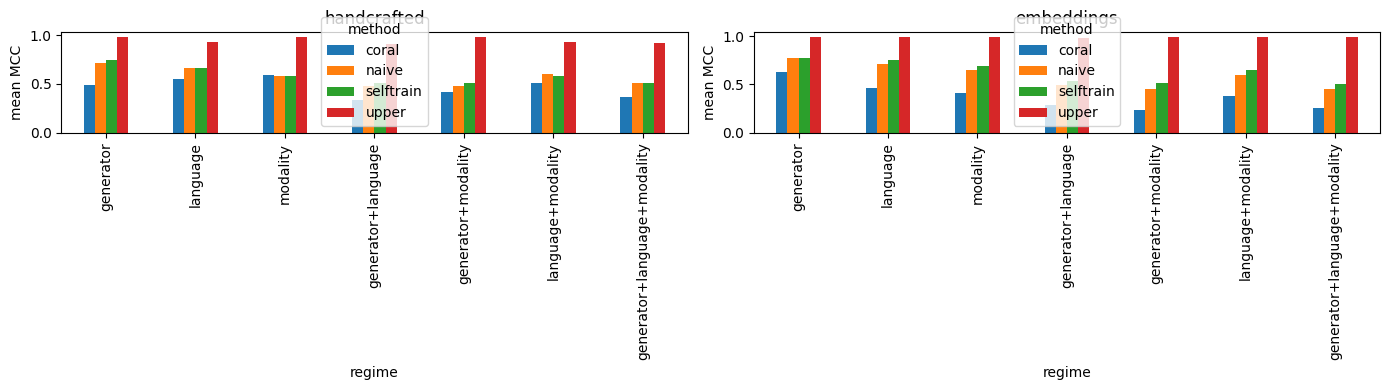

In [14]:
def summarize(res):
    piv = res.pivot_table(index=["rep", "src", "tgt", "regime"], columns="method", values="mcc").reset_index()
    denom = (piv["upper"] - piv["naive"]).replace(0, np.nan)
    piv["recovery_coral"]     = (piv["coral"]     - piv["naive"]) / denom
    piv["recovery_selftrain"] = (piv["selftrain"] - piv["naive"]) / denom
    return piv

if res is not None and not res.empty:
    piv = summarize(res)
    print(piv.groupby(["rep", "regime"])[["naive", "coral", "selftrain", "upper"]].mean().round(3))
    print("\nmean recovery ratio by representation (fraction of gap closed, no target labels):")
    print(piv.groupby("rep")[["recovery_coral", "recovery_selftrain"]].mean().round(3))
    for rep in piv["rep"].unique():
        sub = piv[piv["rep"] == rep]
        a = sub["coral"].dropna(); b = sub["selftrain"].reindex(a.index)
        if len(a) >= 6:
            stat, p = wilcoxon(a, b); print(f"[{rep}] Wilcoxon coral vs selftrain (MCC): p = {p:.4f}")
    piv.to_csv(OUT_DIR / "recovery_summary.csv", index=False)

    import matplotlib.pyplot as plt
    reps = list(res["rep"].unique())
    order = ["intra", "generator", "language", "modality",
             "generator+language", "generator+modality", "language+modality",
             "generator+language+modality"]
    fig, axes = plt.subplots(1, len(reps), figsize=(7*len(reps), 4), squeeze=False)
    for ax, rep in zip(axes[0], reps):
        g = res[res["rep"] == rep].groupby(["regime", "method"]).mcc.mean().unstack()
        g = g.loc[[r for r in order if r in g.index]]
        g.plot(kind="bar", ax=ax); ax.set_title(rep); ax.set_ylabel("mean MCC")
    plt.tight_layout(); plt.savefig(OUT_DIR / "mcc_by_regime.png", dpi=150); plt.show()
else:
    print("No results yet.")

## Part 11 — Checklist before writing Results

- [ ] `MODEL_VERSIONS` filled (exact model + date per generator)
- [ ] ~500+ generated per (generator x language x modality); FR/AR fluency-checked
- [ ] Part 1b ran (FR/AR normalized); EN email+sms downloaded and normalized
- [ ] French SMS: both classes generated (phishing + `legit_*` benign)
- [ ] smoke test passed; `transfer_matrix.csv` + `recovery_summary.csv` saved
- [ ] 17 stylometric features from ref [2] implemented in `numeric_features`
- [ ] (optional) `pip install sentence-transformers` for Representation B (adds the `rep` column = RQ3)

Regimes to expect: generator / language / **modality** / their combinations. The `modality` and `*+modality` rows are your cross-modality generalization result. Bring `transfer_matrix.csv`, `recovery_summary.csv`, `mcc_by_regime.png` back to write Sections 6, 7, 9, Abstract.